#### Objective
- pipelinify & optimize AlosPolarimetric to enable parameter search testing for statistical/empirical identification of algorithmic stability
- replace the clumsy manual Adam optimizer with a torch-based workflow


In [3]:
import os, importlib, netCDF4
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch.nn as nn
import torch

import Model
import PyPreprocess

#MAKE SURE CUDA IS WORKING RIGHT!
print(torch.version.cuda)
print(torch.cuda.is_available())
a = torch.rand(1).cuda()
print(a)

In [4]:
# -- RVILab SPACE SETUP -- #

load_new = False
fn_1 = "/mnt/d/slc_arcticarchi/251010rBanks/ALOS-P1_1__A-ORBIT__ALPSRP172151420.h5"
fn_2 = "/mnt/d/slc_arcticarchi/251010rBanks/ALOS-P1_1__A-ORBIT__ALPSRP174631420.h5"
fn_cache = "ALOSPolarimetric_2510_dataset_cached_Banks.pickle"

if (load_new):
    dataset = PyPreprocess.Pair_Dataset_SNAPh5(fn_1, fn_2, step_azi=20, step_rng=10, rubbersheet=True)
    dataset.cache(fn_cache)
else:
    dataset = PyPreprocess.Pair_Dataset_SNAPh5.load_cache(fn_cache)

fn_it = "cmems_mod_arc_phy_my_nextsim_P1M-m_1760090640041.nc"
data_it = netCDF4.Dataset(fn_it, 'r')
it_ll = np.array(np.meshgrid(data_it.variables['latitude'], data_it.variables['longitude'], indexing='ij'))
#sit_interpolated = data_it.variables['sithick'][0]
print(f"imported {fn_it}")

it_mesh = np.array(np.meshgrid(np.arange(it_ll[0].shape[0]), np.arange(it_ll[0].shape[1]), indexing='ij'))
tmp = (scipy.interpolate.RegularGridInterpolator((it_ll[0].mean(axis=1), it_ll[1].mean(axis=0)), it_mesh[0]),
       scipy.interpolate.RegularGridInterpolator((it_ll[0].mean(axis=1), it_ll[1].mean(axis=0)), it_mesh[1]))
#s1 pixel -> s1 lat/lon -> it pixel
tmp = (tmp[0](np.stack((dataset.lat.ravel(), dataset.lon.ravel()),axis=1)).reshape(dataset.lat.shape),
       tmp[1](np.stack((dataset.lat.ravel(), dataset.lon.ravel()),axis=1)).reshape(dataset.lat.shape))
it_coordmap = tmp
print("finished generating coordinate map.")

# interpolation of parameter
def processAux(auxdata, interpolate_empty=False):
    if (interpolate_empty):
        print("interpolation of null values specified - interpolating values..")
        tmp2 = it_mesh[:,~np.isnan(auxdata)]; tmp2 = np.stack(tmp2.reshape((2, tmp2.size//2)),axis=-1)
        auxdata = scipy.interpolate.LinearNDInterpolator(tmp2, auxdata[~np.isnan(auxdata)].ravel())
        auxdata = auxdata(np.stack(it_mesh.reshape((2,it_mesh.size//2)),axis=-1)).reshape(it_ll[0].shape)
        auxdata[np.isnan(auxdata)] = 0
        print("completed value generation.")
    else:
        auxdata[np.isnan(auxdata)] = 0
    return scipy.ndimage.map_coordinates(auxdata, it_coordmap)

sit = processAux(data_it.variables['sithick'][0])
sic = processAux(data_it.variables['siconc'][0])
sia = processAux(data_it.variables['siage'][0])
sivx = processAux(data_it.variables['vxsi'][0])
sivy = processAux(data_it.variables['vysi'][0])

sigs = dataset.s1.copy(), dataset.s2.copy()
sigs = [np.array([el for el in img] + [img[0]-img[3], img[1]+img[2]]) for img in sigs] #just a few more bands :3
cohs = PyPreprocess.stackcoh(sigs[0], sigs[1], window_size=4)

imported cmems_mod_arc_phy_my_nextsim_P1M-m_1760090640041.nc
finished generating coordinate map.


In [5]:
inds = torch.nn.functional.max_pool2d(torch.rand(cohs[0].shape)[None,:],
                                      (32,8), return_indices=True)[1][0]
#smol_cohs, smol_ia1, smol_kz = cohs[:,inds], dataset.ia1[inds], dataset.k_z[inds]
smol_coh = np.stack([coh.flatten()[inds] for coh in cohs], axis=0)
smol_ia1 = dataset.ia1.flatten()[inds]
smol_k_z = dataset.k_z.flatten()[inds]

In [21]:
importlib.reload(Model)
#p_sim = np.array((sit, sia))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#torch.cuda.empty_cache()
model2 = Model.TorchRVI2(cohs, dataset.ia1, dataset.k_z, wavelength=0.236, vxt_layers=1).to(device)
#model2.to(device)

#optimizer = torch.optim.SGD(model.parameters(), lr=1e1, momentum=0.97)
optimizer = torch.optim.AdamW(model2.parameters(), lr=1e-2, weight_decay=1e-5)#.to(device)
#optim_vxt = torch.optim.AdamW(model2.vxt.parameters(), lr=1e-1, weight_decay=5e-3)
#scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-5)
#sched_vxt = torch.optim.lr_scheduler.CosineAnnealingLR(optim_vxt, T_max=20, eta_min=1e-5)
#[sched_vxt.step() for i in range(10)] # push vxt out of phase with general param (ignore warning)

loss_hist = []

[000/500] Loss: 1.703131e-01
[100/500] Loss: 2.179837e-02
[200/500] Loss: 2.075646e-02
[300/500] Loss: 2.064546e-02
[400/500] Loss: 2.058909e-02


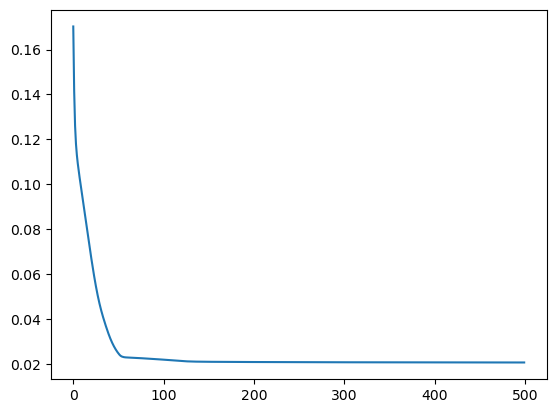

In [22]:
steps = 500
for t in range(steps):
    optimizer.zero_grad()
    modelled = model2.forward()
    captured = model2.data_captured()
    loss = model2.loss_fn(modelled, captured)
    loss.backward()
    optimizer.step()
    #model2.steps += 1
    #scheduler.step()
    #sched_vxt.step()

    # Optional: parameter correction / clamping
    with torch.no_grad():
        model2.sv_ratio.clamp_(0.0, 1.0)
        model2.thickness.clamp_(0.0, 10.0) #0 to 10 metres
        model2.age.clamp_(0.0, 10.0) #0 to 10 years

    if t % 100 == 0:
        print(f"[{t:03d}/{steps}] Loss: {loss.item():.6e}")
    loss_hist.append(loss.item())
plt.plot(loss_hist)

In [12]:
modelled.shape

torch.Size([6, 26, 11])

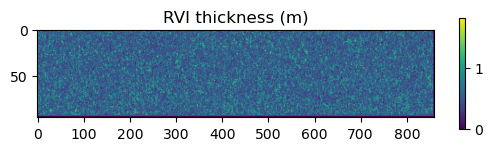

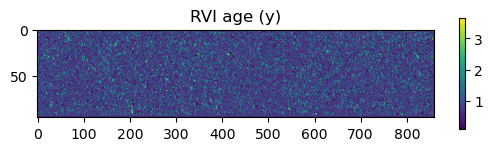

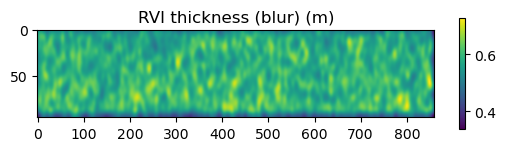

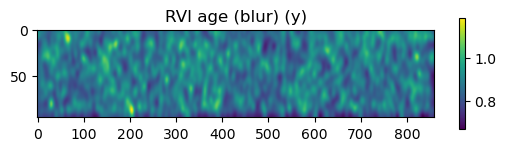

In [23]:
#[(name, torch.isnan(p).any()) for p in model2.parameters()]
def cp_read(x):
    return x.cpu().detach().numpy().T

tmp = cp_read(model2.thickness)
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI thickness (m)"); plt.show()
tmp1 = cp_read(model2.age)
plt.imshow(tmp1, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI age (y)"); plt.show()

tmp = scipy.ndimage.gaussian_filter(tmp, sigma=4, radius=(20,150))
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI thickness (blur) (m)"); plt.show()
tmp = scipy.ndimage.gaussian_filter(tmp1, sigma=4, radius=(20,150))
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI age (blur) (y)"); plt.show()

In [20]:
#tmp = torch.tensor([0.1, 500.0]).unsqueeze(0)
#tmp = torch.ones(5,2) * torch.linspace(0,2,5)[:,None];
#tmp[:,1] = 0.1
#tmp[:,0] = 1
#tmp /= np.max(tmp, axis=0)[None,:]
#plt.imshow(tmp.T); plt.colorbar()
if not os.path.exists('framez'):
    os.makedirs('framez')

tmp_a = torch.zeros(1, 2)
k = 0
tmp_dbins = np.linspace(0,2,20)
tmp_abins = np.linspace(0,2,5)

for i in tmp_dbins:
    tmp_a[0,0] = i
    k += 1
    tmp = []
    for j in tmp_abins:
        tmp_a[0,1] = j
        tmp = model2.vxt.vxt_fnn.forward(tmp_a.to('cuda')).cpu().detach().numpy()
        plt.plot(np.linspace(0,5,16), tmp.T)
    plt.title(f"thickness={round(i,3)}m")
    plt.xlabel("depth (m)"); plt.ylabel("ext (?)")
    plt.legend([f"age {el} y" for el in tmp_abins])
    plt.savefig(f"framez/frame_{k}.png")
    plt.close()
    
import imageio.v2
images = []
for i in range(k):
    filename = f'framez/frame_{i+1}.png'
    images.append(imageio.v2.imread(filename))
images += [images[i] for i in range(len(images)-1, -1, -1)]
imageio.v2.mimsave('animation.gif', images, fps=10, loop=0)

In [1309]:
torch.fft.irfft(torch.linspace(1,10,10)).size()

torch.Size([18])

[000/500] Loss: 4.873077e-02
[100/500] Loss: 4.263389e-02
[200/500] Loss: 4.136381e-02
[300/500] Loss: 4.097901e-02
[400/500] Loss: 4.083658e-02


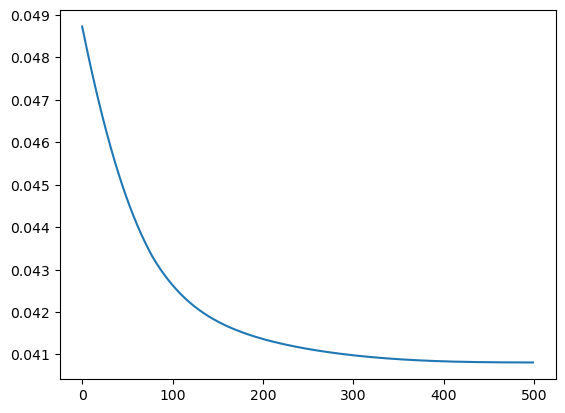

In [193]:
# OLD MODEL

def extinction(z, h, t): return 15*(z/h)/(0.1*t) + 3.1
model = Model.TorchRVI(cohs, dataset.ia1, dataset.k_z, wavelength=0.236)
model.sample_volume_coherence(extinction, hgt_min=0.01, hgt_max=5, hgt_bins=50, age_min=5, age_max=200, age_bins=30, k_z_bins=20)

steps = 500

#optimizer = torch.optim.SGD(model.parameters(), lr=100, momentum=0.97)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=1e-5)
loss_hist = []
for t in range(steps):
    optimizer.zero_grad()
    modelled = model.forward()
    captured = model.data_captured()
    loss = model.loss_fn(modelled, captured)
    loss.backward()
    optimizer.step()
    scheduler.step()

    # Optional: parameter correction / clamping
    with torch.no_grad():
        model.sv_ratio.clamp_(0.0, 1.0)
        model.thickness.clamp_(0.0, 100.0)
        model.age.clamp_(0.0, 100.0)

    if t % 100 == 0:
        print(f"[{t:03d}/{steps}] Loss: {loss.item():.6e}")
    loss_hist.append(loss.item())
plt.plot(loss_hist)

In [ ]:
tmp = model.thickness.detach().numpy().T
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI thickness (m)"); plt.show()
tmp = scipy.ndimage.gaussian_filter(tmp, sigma=4, radius=(20,150))
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI thickness (blur) (m)"); plt.show()
plt.imshow(sit.T, aspect=2); plt.colorbar(shrink=0.3); plt.title("neXtSIM thickness (m)"); plt.show()
plt.imshow(np.abs(dataset.s2[0]).T, aspect=2); plt.colorbar(shrink=0.3); plt.title("s1 HH DN"); plt.show()
plt.imshow(np.abs(dataset.s1[0]).T, aspect=2); plt.colorbar(shrink=0.3); plt.title("s2 HH DN"); plt.show()